# So sánh Label Evidence & Annotation Pilot

Notebook tổng hợp ba nguồn bằng artifact pilot và hàm audit đã triển khai. Số hàng là cửa sổ chọn review, không phải số quan sát độc lập. Tất cả nhãn còn phụ thuộc chứng cứ thực tế; notebook không tự tạo class hoặc đánh giá hazard từ điều kiện sóng.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/pilot.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/pilot.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
from ml.labeling.evidence_audit import audit_label_evidence

ARTIFACT_ROOT = REPO_ROOT / "ml/data/labels/annotation_pilot"
FORM_PATH = ARTIFACT_ROOT / "annotation_pilot.csv"
forms = pd.read_csv(FORM_PATH, keep_default_na=False)
evidence = audit_label_evidence(REPO_ROOT, form_path=FORM_PATH)
print(f"Số hồ sơ pilot hiện có: {len(forms)}")
print(f"Số quyết định reviewer: {evidence['reviewed_decisions']}")


Số hồ sơ pilot hiện có: 92
Số quyết định reviewer: 0


## Độ phủ theo nguồn và session

`reviewed` đếm các quyết định có reviewer/status thực tế. `sessions` là số định danh session khác nhau trong pilot; các nguồn có scale và protocol khác nhau nên không gộp thành một phân bố vật lý chung.

In [2]:
rows = []
for dataset, frame in forms.groupby("dataset_source", sort=True):
    item = evidence["datasets"][dataset]
    reviewed = int(frame.review_status.isin(["ACCEPTED", "REJECTED", "NEEDS_DISCUSSION"]).sum())
    rows.append({"Nguồn": dataset, "Mẫu review (chồng lấn)": len(frame),
        "Session độc lập trong pilot": frame.session_id.nunique(), "Đã review": reviewed,
        "Chưa review": len(frame) - reviewed, "Hazard vận hành có reference xác minh": item["verified_operational_hazard_labels"],
        "Phenotype người review xác nhận": item["human_reviewed_labels"],
        "Session có metadata thử nghiệm": item["sessions_with_experiment_context"]})
comparison = pd.DataFrame(rows).set_index("Nguồn")
display(comparison)


,Mẫu review (chồng lấn),Session độc lập trong pilot,Đã review,Chưa review,Hazard vận hành có reference xác minh,Phenotype người review xác nhận,Session có metadata thử nghiệm
Nguồn,,,,,,,
hohai,84,21,0,84,0,0,21
seafar,4,1,0,4,0,0,0
southampton,4,1,0,4,0,0,1


## Kết quả evidence audit

Metadata Southampton (wave frequency/amplitude) là provenance của điều kiện thử, không phải nhãn. Tên sheet Hohai cũng không ánh xạ trạng thái an toàn. Seafar telemetry không đi kèm event reference trong artifact đã kiểm tra.

In [3]:
for dataset in ("seafar", "hohai", "southampton"):
    item = evidence["datasets"][dataset]
    print(f"{dataset}: {evidence['evidence_conclusions'][dataset]['finding_vi']}")
    print(f"  số session={item['independent_sessions']}, quyết định reviewer={item['reviewed_decisions']}, hazard có reference={item['verified_operational_hazard_labels']}")
    for claim in evidence["evidence_conclusions"][dataset]["unsupported_claims_vi"]:
        print("  - " + claim)


seafar: JSON là telemetry theo thời gian; không thấy trường event/incident/operating-state độc lập. Một session tàu thật; offset gốc và lineage trục/rate cần lưu ý.
  số session=1, quyết định reviewer=0, hazard có reference=0
  - Không thể gọi Roll offset khác 0 là hazard hoặc NORMAL.
  - Không thể kết luận HIGH_ROLL/PERSISTENT_OFFSET/AMPLITUDE_GROWTH từ thống kê đơn lẻ.
hohai: Workbook có 21 sheet/session và tên sheet chứa thông tin berth/test/type; đây là định danh cấu hình thử nghiệm, không phải nhãn trạng thái an toàn. Nguồn là mô hình thử nghiệm, thời gian suy từ 50 Hz; không có timestamp/gyro đo trực tiếp.
  số session=21, quyết định reviewer=0, hazard có reference=0
  - Không diễn giải hậu tố Type_A/B/C thành phenotype/hazard.
  - Không tuyên bố dữ liệu mô hình đại diện trực tiếp cho tàu full-scale.
southampton: Test Plan mô tả điều kiện thử nghiệm theo Run ID; các giá trị wave frequency/amplitude chỉ là provenance. Run 14 có điều kiện trong metadata nhưng không kèm nhãn hazard 

## Tương quan lớp và rủi ro thống kê

Không có quyết định review thì phân bố class để trống/0 theo artifact, không được diễn giải là lớp đó vắng mặt. Review queue được chọn có chủ đích và cửa sổ 180 giây stride 10 giây chồng lấn khoảng 94,4%; không dùng hàng cửa sổ như mẫu độc lập.

In [4]:
status_counts = forms.groupby(["dataset_source", "review_status"], dropna=False).size().rename("Số mẫu").reset_index()
display(status_counts)
print("Tổng quyết định reviewer thực tế:", evidence["reviewed_decisions"])
print("Nhãn có external reference:", evidence["external_reference_labels"])
print("Đồng thuận giữa reviewer:", evidence["inter_reviewer_agreement"]["status"],
      evidence["inter_reviewer_agreement"]["reason_vi"])


,dataset_source,review_status,Số mẫu
0,hohai,PENDING,84
1,seafar,PENDING,4
2,southampton,PENDING,4


Tổng quyết định reviewer thực tế: 0
Nhãn có external reference: 0
Đồng thuận giữa reviewer: NOT_CALCULATED Chưa có ít nhất hai reviewer với quyết định chồng lặp thực tế.


## Bằng chứng hình ảnh

Biểu đồ này được tạo bởi module pilot từ form thực tế. Nó mô tả quy mô queue và số session, không hàm ý số session độc lập về mặt thống kê lớn hơn con số hiển thị.

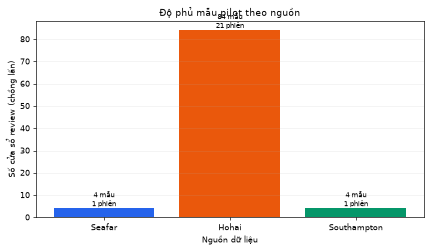

In [5]:
coverage = ARTIFACT_ROOT / "figures/evidence_coverage.png"
if coverage.is_file():
    display(Image(filename=str(coverage)))
else:
    print("Chưa có biểu đồ; chạy `python -m ml.labeling.pilot_run` từ repository root.")


## Giải thích kỹ thuật phục vụ vấn đáp

- **Evidence audit** tìm annotation và metadata độc lập; không biến nguồn dữ liệu hay điều kiện thí nghiệm thành nhãn.
- **Annotation pilot** nối queue với đúng segment/window, đưa Roll/Pitch, context, quality flags và provenance tới reviewer.
- **Quản trị quyết định** giữ decision, evidence category, reviewer, thời gian và audit trail; HUMAN_REVIEWED không đồng nghĩa hazard VERIFIED.
- **Kết quả hiện tại** được tính từ review queue, processed provenance và form/ledger. Nếu không có reviewer, agreement không tính.
- **Hạn chế và bước tới**: cần event log/operating envelope đã xác nhận và ít nhất hai reviewer cùng chấm tập con trước supervised training.